# Data Quality, EDA and Merchant Feature Engineering

## Notebook Purpose

The objective of this project is to support a Buy Now, Pay Later (BNPL) provider in identifying attractive merchants for potential onboarding. Because the final recommendation requires merchants to be ranked, this notebook first examines the quality and structure of the available data and then converts transaction-level information into a curated merchant-level feature dataset.

This notebook focuses on three questions:

1. **Is the cleaned data reliable enough for downstream analysis?**
2. **What patterns and differences exist across transactions and merchants?**
3. **Which merchant characteristics should be carried forward into the ranking stage?**

The final merchant ranking itself is not performed in this notebook. Instead, the output of this notebook is a one-row-per-merchant feature table that will be used in the subsequent ranking and segmentation analysis.

---

## Data Overview

The analysis uses three main cleaned datasets:

| Dataset | Unit of observation | Purpose |
|---|---|---|
| `transactions` | One row per transaction/order | Contains customer, merchant, transaction date and transaction value |
| `merchants` | One row per merchant | Contains merchant metadata, category information and BNPL take rate |
| `consumers` | One row per consumer | Contains consumer information used for validation and downstream demographic analysis |

The transaction dataset spans **28 February 2021 to 26 October 2022**.

After cleaning, the datasets contain:

- **14,195,505 transactions**
- **4,026 merchant records** in the merchant metadata table
- **4,422 distinct merchant ABNs** appearing in transactions
- **499,999 consumer records**
- **24,081 distinct consumers** appearing in the transaction data

The difference between the number of merchant records and merchant ABNs appearing in transactions is investigated later in this notebook.

### Key Transaction Fields

| Variable | Meaning |
|---|---|
| `order_id` | Unique identifier for an individual transaction |
| `user_id` | Identifier for the consumer making the transaction |
| `merchant_abn` | Australian Business Number identifying the merchant |
| `order_datetime` | Date of the transaction |
| `dollar_value` | Dollar value of the transaction |
| `merchant_fraud_probability` | Available merchant fraud-risk estimate |
| `consumer_fraud_probability` | Available consumer fraud-risk estimate |

### Key Merchant Fields

| Variable | Meaning |
|---|---|
| `merchant_abn` | Merchant identifier |
| `name` | Merchant name |
| `keywords_clean` | Cleaned merchant category/description keywords |
| `take_rate` | Percentage of transaction value received by the BNPL provider |

### Abbreviations

- **BNPL** — Buy Now, Pay Later
- **ABN** — Australian Business Number
- **EDA** — Exploratory Data Analysis
- **GMV** — Gross Merchandise Value
- **AOV** — Average Order Value
- **IQR** — Interquartile Range
- **CV** — Coefficient of Variation

---

## Analysis Workflow

The notebook proceeds through the following stages:

**Data integrity and missingness**
→ **Outlier assessment**
→ **Temporal EDA**
→ **Merchant-level EDA**
→ **Commercial and customer feature engineering**
→ **Growth analysis**
→ **History and stability analysis**
→ **Final curated merchant feature dataset**

### Load the Cleaned Dataset

In [8]:
from pyspark.sql import SparkSession, functions as F

spark = (
    SparkSession.builder
    .appName("assignment2_eda")
    .master("local[4]")
    .config("spark.driver.memory", "4g")
    .config("spark.sql.shuffle.partitions", "128")
    .config("spark.sql.adaptive.enabled", "true")
    .getOrCreate()
)

transactions = spark.read.parquet(
    "../data/tables/processed/transactions_clean"
)

merchants = spark.read.parquet(
    "../data/tables/processed/merchants_clean"
)

consumers = spark.read.parquet(
    "../data/tables/processed/consumers"
)

duplicates = spark.read.parquet(
    "../data/tables/processed/duplicate_order_ids"
)

In [9]:
print("Transactions:", transactions.count())
print("Merchants:", merchants.count())
print("Consumers:", consumers.count())

print(
    "Unique orders:",
    transactions.select("order_id").distinct().count()
)

print(
    "Unique merchants in transactions:",
    transactions.select("merchant_abn").distinct().count()
)

print(
    "Unique customers in transactions:",
    transactions.select("user_id").distinct().count()
)

Transactions: 14195505
Merchants: 4026
Consumers: 499999


Unique orders: 14195505
Unique merchants in transactions: 4422
Unique customers in transactions: 24081


### Check join integrity

In [10]:
# Missing Merchant Records
missing_merchants = (
    transactions
    .select("merchant_abn")
    .distinct()
    .join(
        merchants.select("merchant_abn"),
        on="merchant_abn",
        how="left_anti"
    )
)

missing_merchants.count()

# Missing consumer records
missing_consumers = (
    transactions
    .select("user_id")
    .distinct()
    .join(
        consumers.select("user_id"),
        on="user_id",
        how="left_anti"
    )
)

missing_consumers.count()

0

### NULL Overview

In [11]:
transactions = (
    transactions
    .withColumn(
        "consumer_fraud_coverage",
        (
            (F.col("order_datetime") >= F.to_date(F.lit("2021-02-28"))) &
            (F.col("order_datetime") <= F.to_date(F.lit("2022-02-27")))
        ).cast("int")
    )
    .withColumn(
        "merchant_fraud_coverage",
        (
            (F.col("order_datetime") >= F.to_date(F.lit("2021-03-25"))) &
            (F.col("order_datetime") <= F.to_date(F.lit("2022-02-27")))
        ).cast("int")
    )
)

In [12]:
# Consumer fraud missingness within coverage period

(
    transactions
    .filter(F.col("consumer_fraud_coverage") == 1)
    .agg(
        F.count("*").alias("transactions_in_coverage"),

        F.sum(
            F.col("consumer_fraud_probability").isNull().cast("int")
        ).alias("missing"),

        F.round(
            F.avg(
                F.col("consumer_fraud_probability").isNull().cast("int")
            ) * 100,
            2
        ).alias("missing_pct")
    )
    .show()
)

+------------------------+-------+-----------+
|transactions_in_coverage|missing|missing_pct|
+------------------------+-------+-----------+
|                 8151372|8071024|      99.01|
+------------------------+-------+-----------+



In [13]:
# Merchant fraud missingness within coverage period

(
    transactions
    .filter(F.col("merchant_fraud_coverage") == 1)
    .agg(
        F.count("*").alias("transactions_in_coverage"),

        F.sum(
            F.col("merchant_fraud_probability").isNull().cast("int")
        ).alias("missing"),

        F.round(
            F.avg(
                F.col("merchant_fraud_probability").isNull().cast("int")
            ) * 100,
            2
        ).alias("missing_pct")
    )
    .show()
)

+------------------------+-------+-----------+
|transactions_in_coverage|missing|missing_pct|
+------------------------+-------+-----------+
|                 7714197|7710138|      99.95|
+------------------------+-------+-----------+



Missingness was concentrated in the two fraud-probability variables, while the cleaned merchant, consumer, and core transaction fields contained no missing values. Across the full transaction dataset, fraud-score availability was extremely sparse.

Differences in temporal coverage partially explain the missingness. Transactions extend to 26 October 2022, whereas the fraud lookup datasets end on 27 February 2022, meaning fraud scores are unavailable for later transactions. However, missingness remained extremely high even when analysis was restricted to the periods covered by the lookup datasets. Within the consumer fraud coverage period, 8,071,024 of 8,151,372 transactions (99.01%) had no consumer fraud score. Similarly, 7,710,138 of 7,714,197 transactions (99.95%) had no merchant fraud score.

Therefore, temporal coverage alone does not explain the missingness. Fraud-score availability appears to be highly selective and systematic. This is also consistent with the observed differences in transaction values between scored and unscored transactions. Consequently, missing fraud probabilities are retained as missing rather than being replaced with zero or statistically imputed. Fraud-score availability will be treated separately from observed fraud risk in subsequent analysis.

### Check for obviously invalid transaction values

In [14]:
transactions.select("dollar_value").summary().show()

+-------+--------------------+
|summary|        dollar_value|
+-------+--------------------+
|  count|            14195505|
|   mean|  166.22895390892091|
| stddev|   517.8505602612801|
|    min|9.756658099412162E-8|
|    25%|  26.127339090826883|
|    50%|   62.22295741533169|
|    75%|  150.43524086603603|
|    max|  105193.88578925544|
+-------+--------------------+



In [15]:
transactions.agg(
    F.min("dollar_value").alias("min"),
    F.max("dollar_value").alias("max"),
    F.avg("dollar_value").alias("mean"),
    F.count("*").alias("n"),
    F.sum((F.col("dollar_value") <= 0).cast("int")).alias("non_positive")
).show()

+--------------------+------------------+------------------+--------+------------+
|                 min|               max|              mean|       n|non_positive|
+--------------------+------------------+------------------+--------+------------+
|9.756658099412162E-8|105193.88578925544|166.22895390892091|14195505|           0|
+--------------------+------------------+------------------+--------+------------+



In [16]:
transactions.filter(
    F.col("dollar_value") <= 0
).show(20, truncate=False)

+-------+--------------+------------+------------+--------+-------------+--------------------------+--------------------------+-----------------------+-----------------------+
|user_id|order_datetime|merchant_abn|dollar_value|order_id|_source_order|merchant_fraud_probability|consumer_fraud_probability|consumer_fraud_coverage|merchant_fraud_coverage|
+-------+--------------+------------+------------+--------+-------------+--------------------------+--------------------------+-----------------------+-----------------------+
+-------+--------------+------------+------------+--------+-------------+--------------------------+--------------------------+-----------------------+-----------------------+



### Transaction value percentile

In [17]:
quantiles = transactions.approxQuantile(
    "dollar_value",
    [
        0.00,
        0.01,
        0.05,
        0.25,
        0.50,
        0.75,
        0.90,
        0.95,
        0.99,
        0.999,
        1.00
    ],
    0.001
)

labels = [
    "Min",
    "1%",
    "5%",
    "25%",
    "Median",
    "75%",
    "90%",
    "95%",
    "99%",
    "99.9%",
    "Max"
]

for label, value in zip(labels, quantiles):
    print(f"{label:>7}: ${value:,.2f}")

    Min: $0.00
     1%: $1.23
     5%: $5.45
    25%: $26.07
 Median: $62.18
    75%: $150.21
    90%: $357.90
    95%: $587.40
    99%: $1,587.06
  99.9%: $105,193.89
    Max: $105,193.89


### Convention IQR Threshold

In [18]:
q1, q3 = transactions.approxQuantile(
    "dollar_value",
    [0.25, 0.75],
    0.001
)

iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

print(f"Q1: ${q1:,.2f}")
print(f"Q3: ${q3:,.2f}")
print(f"IQR: ${iqr:,.2f}")
print(f"Lower bound: ${lower_bound:,.2f}")
print(f"Upper bound: ${upper_bound:,.2f}")

Q1: $26.07
Q3: $150.21
IQR: $124.15
Lower bound: $-160.15
Upper bound: $336.43


In [19]:
transactions.agg(
    F.count("*").alias("total"),

    F.sum(
        (F.col("dollar_value") > upper_bound).cast("int")
    ).alias("upper_outliers"),

    F.sum(
        (F.col("dollar_value") < lower_bound).cast("int")
    ).alias("lower_outliers")
).show()

+--------+--------------+--------------+
|   total|upper_outliers|lower_outliers|
+--------+--------------+--------------+
|14195505|       1536952|             0|
+--------+--------------+--------------+



In [20]:
(
    transactions
    .agg(
        F.round(
            F.avg(
                (
                    (F.col("dollar_value") > upper_bound) |
                    (F.col("dollar_value") < lower_bound)
                ).cast("int")
            ) * 100,
            2
        ).alias("outlier_pct")
    )
    .show()
)

+-----------+
|outlier_pct|
+-----------+
|      10.83|
+-----------+



### Inspect Largest Transactions

In [21]:
(
    transactions
    .orderBy(F.desc("dollar_value"))
    .select(
        "order_id",
        "order_datetime",
        "user_id",
        "merchant_abn",
        "dollar_value"
    )
    .show(30, truncate=False)
)

+------------------------------------+--------------+-------+------------+------------------+
|order_id                            |order_datetime|user_id|merchant_abn|dollar_value      |
+------------------------------------+--------------+-------+------------+------------------+
|2ab65c8f-11b2-41cb-8889-001ce62c005d|2021-04-17    |3101   |91880575299 |105193.88578925544|
|4091b4ae-a26b-478c-b652-39369b0dfb24|2021-12-19    |6228   |82999039227 |77320.86980270348 |
|8584d8d1-061b-41ca-a6d2-5371fff97764|2021-07-27    |11702  |53918538787 |77134.2146046811  |
|fe9edd35-c895-410a-9cb2-651a88d5b688|2022-09-23    |21751  |83199298021 |71382.17605383882 |
|079cc8aa-eadd-4f36-9f09-4571254c9989|2021-12-10    |21419  |23686790459 |67706.74019097649 |
|1d8f2322-d8c8-46cc-b504-d0eda7237e2f|2021-08-26    |23700  |11590404675 |65660.03308418578 |
|c8ec3d69-eb75-4429-942e-65cbcf9d388e|2022-04-22    |3489   |58495294020 |64309.577211019314|
|61fe4fa3-f199-4a16-81ac-4ead1f2bea79|2021-08-08    |18916  

In [22]:
# Join the merchant information
largest_transactions = (
    transactions
    .join(
        merchants.select(
            "merchant_abn",
            "name",
            "keywords_clean",
            "revenue_code",
            "take_rate"
        ),
        on="merchant_abn",
        how="left"
    )
    .orderBy(F.desc("dollar_value"))
)

largest_transactions.select(
    "order_datetime",
    "merchant_abn",
    "name",
    "keywords_clean",
    "dollar_value"
).show(50, truncate=False)

+--------------+------------+------------------------------+---------------------------------------------------------+------------------+
|order_datetime|merchant_abn|name                          |keywords_clean                                           |dollar_value      |
+--------------+------------+------------------------------+---------------------------------------------------------+------------------+
|2021-04-17    |91880575299 |At Foundation                 |[antique shops - sales, repair, and restoration services]|105193.88578925544|
|2021-12-19    |82999039227 |NULL                          |NULL                                                     |77320.86980270348 |
|2021-07-27    |53918538787 |In Tempus Inc.                |[antique shops - sales, repair, and restoration services]|77134.2146046811  |
|2022-09-23    |83199298021 |Ligula Elit Pretium Foundation|[antique shops - sales, repair, and restoration services]|71382.17605383882 |
|2021-12-10    |23686790459 |NULL 

### Merchant level transaction distribution

In [23]:
merchant_stats = (
    transactions
    .groupBy("merchant_abn")
    .agg(
        F.count("*").alias("transaction_count"),
        F.avg("dollar_value").alias("mean_value"),
        F.stddev("dollar_value").alias("sd_value"),
        F.min("dollar_value").alias("min_value"),
        F.max("dollar_value").alias("max_value")
    )
    .withColumn(
        "max_to_mean_ratio",
        F.col("max_value") / F.col("mean_value")
    )
)

In [24]:
merchant_stats = (
    merchant_stats
    .join(
        merchants.select(
            "merchant_abn",
            "name",
            "keywords_clean"
        ),
        on="merchant_abn",
        how="left"
    )
)

### Merchant with largest transactions


In [25]:
(
    merchant_stats
    .orderBy(F.desc("max_value"))
    .select(
        "merchant_abn",
        "name",
        "keywords_clean",
        "transaction_count",
        "mean_value",
        "max_value",
        "max_to_mean_ratio"
    )
    .show(30, truncate=False)
)

+------------+------------------------------+---------------------------------------------------------+-----------------+------------------+------------------+------------------+
|merchant_abn|name                          |keywords_clean                                           |transaction_count|mean_value        |max_value         |max_to_mean_ratio |
+------------+------------------------------+---------------------------------------------------------+-----------------+------------------+------------------+------------------+
|91880575299 |At Foundation                 |[antique shops - sales, repair, and restoration services]|33               |20250.295557031903|105193.88578925544|5.194683973524866 |
|82999039227 |NULL                          |NULL                                                     |93               |16111.161900952842|77320.86980270348 |4.799211272163467 |
|53918538787 |In Tempus Inc.                |[antique shops - sales, repair, and restoration services]|11

### Transactions that are extreme relative to the merchant

In [26]:
(
    merchant_stats
    .filter(F.col("transaction_count") >= 30)
    .orderBy(F.desc("max_to_mean_ratio"))
    .select(
        "merchant_abn",
        "name",
        "keywords_clean",
        "transaction_count",
        "mean_value",
        "max_value",
        "max_to_mean_ratio"
    )
    .show(30, truncate=False)
)

+------------+---------------------------------+---------------------------------------------------------------------------------------+-----------------+------------------+------------------+------------------+
|merchant_abn|name                             |keywords_clean                                                                         |transaction_count|mean_value        |max_value         |max_to_mean_ratio |
+------------+---------------------------------+---------------------------------------------------------------------------------------+-----------------+------------------+------------------+------------------+
|48534649627 |Dignissim Maecenas Foundation    |[optician, optical goods, and eyeglasses]                                              |66437            |141.62226350894298|2100.5117482211763|14.83179054039435 |
|45629217853 |Lacus Consulting                 |[gift, card, novelty, and souvenir shops]                                              |228255          

Transaction values were highly right-skewed, and a conventional global IQR rule identified purchases above approximately $336.90 as outliers. However, merchant-level inspection showed that many of the largest transactions were associated with high-value merchant categories such as antique shops, jewellery retailers, art dealers and related businesses. For example, the largest transaction was approximately $105,194 at an antique merchant whose average transaction value was already approximately $20,250. Therefore, large absolute transaction values were not considered sufficient evidence of erroneous data.

Merchants with the largest maximum-to-mean ratios were also examined. Although some maximum purchases were around 12–15 times the merchant mean, these were generally much smaller in absolute value and remained plausible given normal variation in customer spending. Consequently, transaction-value outliers were retained rather than removed solely on the basis of a global statistical threshold.

### Checking for missing merchant metadata

In [27]:
missing_merchant_metadata = (
    transactions
    .select("merchant_abn")
    .distinct()
    .join(
        merchants.select("merchant_abn"),
        on="merchant_abn",
        how="left_anti"
    )
)

print(
    "Transaction merchants missing from merchant table:",
    missing_merchant_metadata.count()
)

missing_merchant_metadata.show(30, truncate=False)

Transaction merchants missing from merchant table: 396
+------------+
|merchant_abn|
+------------+
|83740063335 |
|84682880992 |
|82774123839 |
|16496390781 |
|40284000376 |
|90827737722 |
|27130058170 |
|96129954993 |
|20890410130 |
|79251685752 |
|95463427236 |
|53764119144 |
|23618059522 |
|24403499052 |
|57241240228 |
|46765707573 |
|63248668429 |
|70893541900 |
|46572791797 |
|24786876262 |
|11839682616 |
|23142656360 |
|99256510843 |
|48539533779 |
|71091910300 |
|83893827922 |
|19142852082 |
|13129485817 |
|89738742187 |
|87767413481 |
+------------+
only showing top 30 rows


In [28]:
(
    transactions
    .join(
        missing_merchant_metadata,
        on="merchant_abn",
        how="inner"
    )
    .agg(
        F.count("*").alias("transactions"),
        F.countDistinct("merchant_abn").alias("merchants"),
        F.sum("dollar_value").alias("total_value")
    )
    .show()
)

+------------+---------+--------------------+
|transactions|merchants|         total_value|
+------------+---------+--------------------+
|      580830|      396|2.0264815374292016E8|
+------------+---------+--------------------+



A total of 396 merchant ABNs appearing in the transaction data were not present in the merchant metadata table. These unmatched merchants accounted for 580,830 transactions, approximately 4.09% of all transactions, and approximately $202.65 million in transaction value. The transactions were retained because their transaction fields were valid, but merchant-level attributes such as merchant name, category and take rate were unavailable. These merchants were therefore excluded only from analyses requiring merchant metadata.

### Transactions under $1 and $5

In [29]:
transactions.agg(
    F.sum(
        (F.col("dollar_value") < 0.01).cast("int")
    ).alias("below_1_cent"),

    F.sum(
        (F.col("dollar_value") < 1).cast("int")
    ).alias("below_1_dollar"),

    F.sum(
        (F.col("dollar_value") < 5).cast("int")
    ).alias("below_5_dollars")
).show()

+------------+--------------+---------------+
|below_1_cent|below_1_dollar|below_5_dollars|
+------------+--------------+---------------+
|        1024|        112368|         638997|
+------------+--------------+---------------+



In [30]:
(
    transactions
    .filter(F.col("dollar_value") < 0.01)
    .orderBy("dollar_value")
    .select(
        "order_id",
        "order_datetime",
        "user_id",
        "merchant_abn",
        "dollar_value"
    )
    .show(30, truncate=False)
)

+------------------------------------+--------------+-------+------------+---------------------+
|order_id                            |order_datetime|user_id|merchant_abn|dollar_value         |
+------------------------------------+--------------+-------+------------+---------------------+
|6e88bd40-8e1b-412d-919d-bc960835ae78|2021-08-19    |6689   |38638753805 |9.756658099412162E-8 |
|2f133008-3073-4901-b72f-dea05862602f|2022-04-24    |13219  |91923722701 |7.37989805475434E-7  |
|c90d9a99-7afd-4e28-9835-10703b4b46c4|2021-11-22    |5352   |67794222692 |6.580118222113988E-6 |
|f1536f71-06c5-4992-826c-23fc0feb289f|2021-12-24    |13782  |69703285964 |2.5159922931758712E-5|
|ecc76ec0-6ff5-4f47-aa2d-99c47c1e746f|2021-10-03    |20446  |32530636640 |2.5832841474875385E-5|
|fcceabe8-7fcd-4690-bdca-aa02b6b1b478|2022-05-02    |476    |80682333501 |2.9909139277637005E-5|
|f7db6cab-0772-41b9-b708-a2245fccae5c|2022-06-06    |11148  |80324045558 |4.541625573152713E-5 |
|1620e03a-6a44-4ab6-9647-73a4c

In [31]:
(
    transactions
    .filter(F.col("dollar_value") < 0.01)
    .groupBy("merchant_abn")
    .agg(
        F.count("*").alias("tiny_transactions")
    )
    .orderBy(F.desc("tiny_transactions"))
    .show(30, truncate=False)
)

+------------+-----------------+
|merchant_abn|tiny_transactions|
+------------+-----------------+
|63290521567 |77               |
|46804135891 |72               |
|45629217853 |68               |
|80324045558 |53               |
|20985347699 |51               |
|91923722701 |50               |
|19933438190 |50               |
|17324645993 |46               |
|80682333501 |29               |
|70038202360 |19               |
|62694031334 |17               |
|37687523474 |13               |
|41251795489 |13               |
|22059270846 |12               |
|75034515922 |12               |
|38638753805 |12               |
|11566786699 |11               |
|61991570212 |10               |
|32530636640 |10               |
|63465140133 |10               |
|29521780474 |9                |
|45466221547 |9                |
|71528203369 |9                |
|58476363584 |9                |
|43061683632 |9                |
|21025433654 |9                |
|18305506006 |8                |
|578249957

In [32]:
transactions = transactions.withColumn(
    "sub_cent_value",
    (F.col("dollar_value") < 0.01).cast("int")
)

Transaction values exhibited a strongly right-skewed distribution, but both upper- and lower-tail observations were investigated before considering removal. Large transactions were generally consistent with merchant type; for example, many of the highest-value purchases occurred at antique, jewellery and art-related merchants whose typical transaction values were also high. Therefore, observations were not removed solely for exceeding the global IQR threshold.

At the lower tail, 1,024 transactions (approximately 0.007% of the dataset) had values below one cent. These observations were distributed across multiple merchants rather than concentrated within a single merchant, suggesting that they likely reflect the tail of the synthetic data-generating process rather than a localised data-quality error. As their prevalence and financial contribution were negligible, the original values were retained and flagged rather than removed.

### Monthly transaction activity

In [33]:
transactions_time = (
    transactions
    .withColumn(
        "month",
        F.date_trunc("month", F.col("order_datetime"))
    )
)

In [34]:
monthly_activity = (
    transactions_time
    .groupBy("month")
    .agg(
        F.count("*").alias("transaction_count"),
        F.sum("dollar_value").alias("total_value"),
        F.avg("dollar_value").alias("avg_transaction_value"),
        F.countDistinct("user_id").alias("unique_customers"),
        F.countDistinct("merchant_abn").alias("active_merchants")
    )
    .orderBy("month")
)

In [35]:
monthly_activity.show(30, truncate=False)

+-------------------+-----------------+--------------------+---------------------+----------------+----------------+
|month              |transaction_count|total_value         |avg_transaction_value|unique_customers|active_merchants|
+-------------------+-----------------+--------------------+---------------------+----------------+----------------+
|2021-02-01 00:00:00|17107            |2784089.493476757   |162.74563006235792   |12259           |2019            |
|2021-03-01 00:00:00|546333           |9.108158117900082E7 |166.7144052784672    |24081           |3975            |
|2021-04-01 00:00:00|560680           |9.311185361582886E7 |166.06951133592932   |24081           |4003            |
|2021-05-01 00:00:00|636666           |1.0600091336339606E8|166.49375553806243   |24081           |4037            |
|2021-06-01 00:00:00|627148           |1.0361150741815731E8|165.21061602390074   |24081           |4028            |
|2021-07-01 00:00:00|655279           |1.0961820831448385E8|167.

In [36]:
monthly_pd = monthly_activity.toPandas()

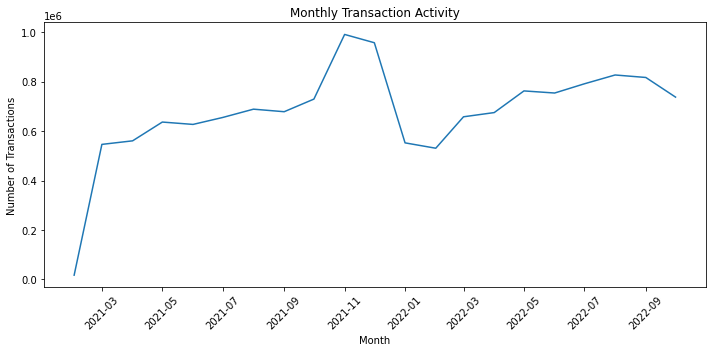

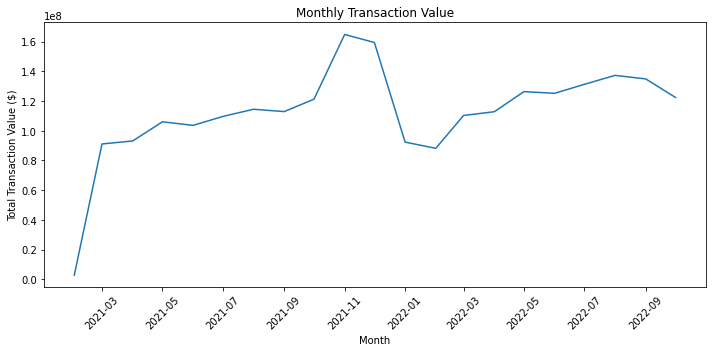

In [37]:
# Plot
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    monthly_pd["month"],
    monthly_pd["transaction_count"]
)

plt.xlabel("Month")
plt.ylabel("Number of Transactions")
plt.title("Monthly Transaction Activity")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))

plt.plot(
    monthly_pd["month"],
    monthly_pd["total_value"]
)

plt.xlabel("Month")
plt.ylabel("Total Transaction Value ($)")
plt.title("Monthly Transaction Value")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [38]:
monthly_activity = (
    monthly_activity
    .withColumn(
        "complete_month",
        ~(
            (F.year("month") == 2022) &
            (F.month("month") == 10)
        )
    )
)

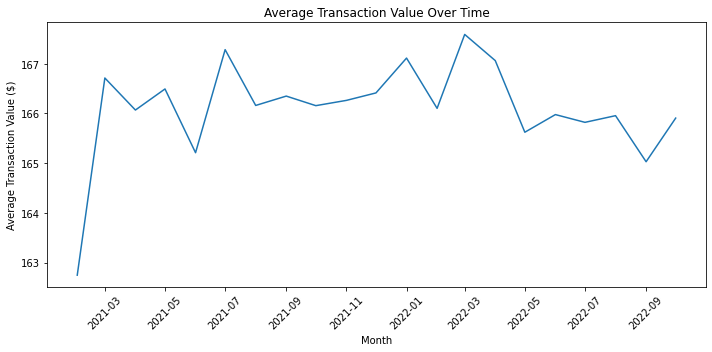

In [39]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_pd["month"],
    monthly_pd["avg_transaction_value"]
)

plt.xlabel("Month")
plt.ylabel("Average Transaction Value ($)")
plt.title("Average Transaction Value Over Time")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Monthly transaction activity varied substantially over the observation period, with transaction volume increasing through much of 2021 and peaking in November 2021 before declining sharply in January and February 2022. Activity subsequently recovered and increased through mid-2022. Total transaction value closely followed transaction volume, whereas average transaction value remained relatively stable at approximately $165–$168. This indicates that variation in monthly transaction value was primarily driven by changes in transaction frequency rather than changes in purchase size. February 2021 and October 2022 represent incomplete months and were therefore not interpreted as genuine changes in activity. The number of unique consumers was almost constant across complete months, consistent with the synthetic nature of the dataset.

### Merchant Level EDA

In [40]:
merchant_eda = (
    transactions
    .groupBy("merchant_abn")
    .agg(
        F.count("*").alias("transaction_count"),
        F.sum("dollar_value").alias("total_value"),
        F.avg("dollar_value").alias("avg_transaction_value"),
        F.countDistinct("user_id").alias("unique_customers")
    )
)

In [41]:
merchant_eda = (
    merchant_eda
    .join(
        merchants.select(
            "merchant_abn",
            "name",
            "keywords_clean",
            "take_rate"
        ),
        on="merchant_abn",
        how="left"
    )
)

In [42]:
merchant_eda = (
    merchant_eda
    .withColumn(
        "estimated_bnpl_revenue",
        F.col("total_value") * (F.col("take_rate") / 100)
    )
)

In [43]:
merchants.select("take_rate").summary().show()

+-------+------------------+
|summary|         take_rate|
+-------+------------------+
|  count|              4026|
|   mean| 4.397575757575771|
| stddev|1.7825953679430926|
|    min|               0.1|
|    25%|              2.97|
|    50%|               4.5|
|    75%|              6.03|
|    max|               7.0|
+-------+------------------+



### Largest merchants by transaction value

In [44]:
(
    merchant_eda
    .orderBy(F.desc("total_value"))
    .select(
        "merchant_abn",
        "name",
        "keywords_clean",
        "transaction_count",
        "unique_customers",
        "avg_transaction_value",
        "total_value"
    )
    .show(20, truncate=False)
)

+------------+-----------------------------+---------------------------------------------------------------------------------------+-----------------+----------------+---------------------+-----------------+
|merchant_abn|name                         |keywords_clean                                                                         |transaction_count|unique_customers|avg_transaction_value|total_value      |
+------------+-----------------------------+---------------------------------------------------------------------------------------+-----------------+----------------+---------------------+-----------------+
|39649557865 |Arcu Morbi Institute         |[artist supply and craft shops]                                                        |21919            |14462           |449.71952772076105   |9857402.328111362|
|96680767841 |Ornare Limited               |[motor vehicle supplies and new parts]                                                 |31134            |17471           |3

### Largest merchants by customer base

In [45]:
(
    merchant_eda
    .orderBy(F.desc("unique_customers"))
    .select(
        "merchant_abn",
        "name",
        "keywords_clean",
        "unique_customers",
        "transaction_count",
        "total_value"
    )
    .show(20, truncate=False)
)

+------------+---------------------------------+---------------------------------------------------------------+----------------+-----------------+------------------+
|merchant_abn|name                             |keywords_clean                                                 |unique_customers|transaction_count|total_value       |
+------------+---------------------------------+---------------------------------------------------------------+----------------+-----------------+------------------+
|64203420245 |Pede Nonummy Corp.               |[tent and awning shops]                                        |24081           |260780           |7549445.230212999 |
|45629217853 |Lacus Consulting                 |[gift, card, novelty, and souvenir shops]                      |24081           |228255           |8395062.46219806  |
|86578477987 |Leo In Consulting                |[watch, clock, and jewelry repair shops]                       |24081           |272674           |9539822.77287039  

### Highest-frequency merchants

In [46]:
(
    merchant_eda
    .orderBy(F.desc("transaction_count"))
    .select(
        "merchant_abn",
        "name",
        "keywords_clean",
        "transaction_count",
        "unique_customers",
        "avg_transaction_value",
        "total_value"
    )
    .show(20, truncate=False)
)

+------------+---------------------------------+---------------------------------------------------------------+-----------------+----------------+---------------------+------------------+
|merchant_abn|name                             |keywords_clean                                                 |transaction_count|unique_customers|avg_transaction_value|total_value       |
+------------+---------------------------------+---------------------------------------------------------------+-----------------+----------------+---------------------+------------------+
|24852446429 |Erat Vitae LLP                   |[florists supplies, nursery stock, and flowers]                |289513           |24080           |30.046248362640224   |8698779.502213059 |
|86578477987 |Leo In Consulting                |[watch, clock, and jewelry repair shops]                       |272674           |24081           |34.98618413515917    |9539822.772870392 |
|64203420245 |Pede Nonummy Corp.               |[tent a

### Transaction per customers

In [47]:
merchant_eda = (
    merchant_eda
    .withColumn(
        "transactions_per_customer",
        F.col("transaction_count") / F.col("unique_customers")
    )
)

In [48]:
# Customer Penetration
TOTAL_CUSTOMERS = 24081

merchant_eda = (
    merchant_eda
    .withColumn(
        "customer_penetration",
        F.col("unique_customers") / F.lit(TOTAL_CUSTOMERS)
    )
)

In [49]:
# Repeat Engagement Merchants
(
    merchant_eda
    .orderBy(F.desc("transactions_per_customer"))
    .select(
        "merchant_abn",
        "name",
        "keywords_clean",
        "transaction_count",
        "unique_customers",
        "transactions_per_customer",
        "avg_transaction_value",
        "total_value"
    )
    .show(20, truncate=False)
)

+------------+---------------------------------+---------------------------------------------------------------+-----------------+----------------+-------------------------+---------------------+------------------+
|merchant_abn|name                             |keywords_clean                                                 |transaction_count|unique_customers|transactions_per_customer|avg_transaction_value|total_value       |
+------------+---------------------------------+---------------------------------------------------------------+-----------------+----------------+-------------------------+---------------------+------------------+
|24852446429 |Erat Vitae LLP                   |[florists supplies, nursery stock, and flowers]                |289513           |24080           |12.02296511627907        |30.046248362640224   |8698779.502213059 |
|86578477987 |Leo In Consulting                |[watch, clock, and jewelry repair shops]                       |272674           |24081     

Repeat purchasing varied substantially across merchants. The highest-engagement merchants recorded approximately 8–12 transactions per customer, despite generally having relatively low average transaction values. This suggests that merchant attractiveness may arise from either high-value purchases or frequent repeat activity, reinforcing the need for a multi-dimensional ranking system rather than relying on total transaction value alone.

### Estimated BNPL revenue ranking

In [50]:
(
    merchant_eda
    .filter(F.col("estimated_bnpl_revenue").isNotNull())
    .orderBy(F.desc("estimated_bnpl_revenue"))
    .select(
        "merchant_abn",
        "name",
        "keywords_clean",
        "total_value",
        "take_rate",
        "estimated_bnpl_revenue",
        "transaction_count",
        "unique_customers",
        "transactions_per_customer",
        "avg_transaction_value"
    )
    .show(20, truncate=False)
)

+------------+-----------------------------+---------------------------------------------------------------------------------------+------------------+---------+----------------------+-----------------+----------------+-------------------------+---------------------+
|merchant_abn|name                         |keywords_clean                                                                         |total_value       |take_rate|estimated_bnpl_revenue|transaction_count|unique_customers|transactions_per_customer|avg_transaction_value|
+------------+-----------------------------+---------------------------------------------------------------------------------------+------------------+---------+----------------------+-----------------+----------------+-------------------------+---------------------+
|79827781481 |Amet Risus Inc.              |[furniture, home furnishings and equipment shops, and manufacturers, except appliances]|9734168.47841823  |6.82     |663870.2902281232     |4798        

Incorporating merchant take rates changed the relative attractiveness of merchants compared with ranking by transaction value alone. For example, Amet Risus Inc. generated approximately $9.73 million in transaction value and, with a 6.82% take rate, produced the highest estimated BNPL revenue of approximately $663,870. This demonstrates that transaction value and take rate jointly determine the direct commercial value of a merchant partnership. 

### Merchant Feature Engineering

### Keep commercial features

In [51]:
merchant_features = (
    merchant_eda
    .select(
        "merchant_abn",
        "name",
        "keywords_clean",
        "take_rate",

        "transaction_count",
        "total_value",
        "avg_transaction_value",
        "unique_customers",
        "transactions_per_customer",
        "customer_penetration",
        "estimated_bnpl_revenue"
    )
)

### Merchant growth

In [52]:
# 1. Monthly merchant activity

merchant_monthly = (
    transactions
    .withColumn(
        "month",
        F.date_trunc("month", F.col("order_datetime"))
    )
    .groupBy("merchant_abn", "month")
    .agg(
        F.sum("dollar_value").alias("monthly_value"),
        F.count("*").alias("monthly_transactions"),
        F.countDistinct("user_id").alias("monthly_customers")
    )
    .filter(
        ~(
            ((F.year("month") == 2021) & (F.month("month") == 2)) |
            ((F.year("month") == 2022) & (F.month("month") == 10))
        )
    )
)

In [53]:
# 2. Early 3-month period: Mar-May 2021
early = (
    transactions
    .filter(
        (F.col("order_datetime") >= F.lit("2021-03-01")) &
        (F.col("order_datetime") < F.lit("2021-06-01"))
    )
    .groupBy("merchant_abn")
    .agg(
        F.sum("dollar_value").alias("early_3m_value"),
        F.count("*").alias("early_3m_transactions"),
        F.countDistinct(
            F.date_trunc("month", "order_datetime")
        ).alias("early_active_months")
    )
)

In [54]:
# 3. Recent 3-month period: Jul-Sep 2022
recent = (
    transactions
    .filter(
        (F.col("order_datetime") >= F.lit("2022-07-01")) &
        (F.col("order_datetime") < F.lit("2022-10-01"))
    )
    .groupBy("merchant_abn")
    .agg(
        F.sum("dollar_value").alias("recent_3m_value"),
        F.count("*").alias("recent_3m_transactions"),
        F.countDistinct(
            F.date_trunc("month", "order_datetime")
        ).alias("recent_active_months")
    )
)

In [55]:
# 4. Combine periods
merchant_growth = (
    early
    .join(
        recent,
        on="merchant_abn",
        how="full"
    )
    .fillna({
        "early_3m_value": 0.0,
        "early_3m_transactions": 0,
        "early_active_months": 0,
        "recent_3m_value": 0.0,
        "recent_3m_transactions": 0,
        "recent_active_months": 0
    })
)

In [56]:
merchant_growth = (
    merchant_growth
    .withColumn(
        "growth_status",
        F.when(
            (F.col("early_active_months") == 0) &
            (F.col("recent_active_months") > 0),
            "new_or_late_entry"
        )
        .when(
            (F.col("early_active_months") > 0) &
            (F.col("recent_active_months") == 0),
            "inactive_recently"
        )
        .when(
            (F.col("early_active_months") >= 2) &
            (F.col("recent_active_months") >= 2),
            "comparable"
        )
        .otherwise("limited_history")
    )
)

In [57]:
# Use log
merchant_growth = (
    merchant_growth
    .withColumn(
        "log_value_growth",
        F.when(
            F.col("growth_status") == "comparable",
            F.log1p(F.col("recent_3m_value")) -
            F.log1p(F.col("early_3m_value"))
        )
    )
)

In [58]:
# Add active months
active_months = (
    merchant_monthly
    .groupBy("merchant_abn")
    .agg(
        F.countDistinct("month").alias("active_months")
    )
)

merchant_growth = (
    merchant_growth
    .join(
        active_months,
        on="merchant_abn",
        how="left"
    )
)

In [59]:
merchant_features = (
    merchant_eda
    .join(
        merchant_growth.select(
            "merchant_abn",

            "early_3m_value",
            "recent_3m_value",

            "early_3m_transactions",
            "recent_3m_transactions",

            "early_active_months",
            "recent_active_months",

            "growth_status",
            "log_value_growth",
            "active_months"
        ),
        on="merchant_abn",
        how="left"
    )
)

In [60]:
# Fastest-growing comparable merchants
(
    merchant_features
    .filter(F.col("growth_status") == "comparable")
    .orderBy(F.desc("log_value_growth"))
    .select(
        "merchant_abn",
        "name",
        "keywords_clean",
        "early_3m_value",
        "recent_3m_value",
        "log_value_growth",
        "early_3m_transactions",
        "recent_3m_transactions",
        "early_active_months",
        "recent_active_months",
        "active_months"
    )
    .show(20, truncate=False)
)

+------------+----------------------------------------+---------------------------------------------------------------+------------------+------------------+------------------+---------------------+----------------------+-------------------+--------------------+-------------+
|merchant_abn|name                                    |keywords_clean                                                 |early_3m_value    |recent_3m_value   |log_value_growth  |early_3m_transactions|recent_3m_transactions|early_active_months|recent_active_months|active_months|
+------------+----------------------------------------+---------------------------------------------------------------+------------------+------------------+------------------+---------------------+----------------------+-------------------+--------------------+-------------+
|24462154202 |Cursus Limited                          |[hobby, toy and game shops]                                    |612.4531370738993 |9155.110959879337 |2.7030729247

In [61]:
# Most-declining comparable merchants
(
    merchant_features
    .filter(F.col("growth_status") == "comparable")
    .orderBy(F.asc("log_value_growth"))
    .select(
        "merchant_abn",
        "name",
        "keywords_clean",
        "early_3m_value",
        "recent_3m_value",
        "log_value_growth",
        "early_3m_transactions",
        "recent_3m_transactions",
        "early_active_months",
        "recent_active_months",
        "active_months"
    )
    .show(20, truncate=False)
)

+------------+------------------------------+---------------------------------------------------------------------------------------+------------------+------------------+-------------------+---------------------+----------------------+-------------------+--------------------+-------------+
|merchant_abn|name                          |keywords_clean                                                                         |early_3m_value    |recent_3m_value   |log_value_growth   |early_3m_transactions|recent_3m_transactions|early_active_months|recent_active_months|active_months|
+------------+------------------------------+---------------------------------------------------------------------------------------+------------------+------------------+-------------------+---------------------+----------------------+-------------------+--------------------+-------------+
|89575340835 |Sodales Mauris Corp.          |[hobby, toy and game shops]                                                    

In [62]:
# New / late-entry merchants
(
    merchant_features
    .filter(F.col("growth_status") == "new_or_late_entry")
    .orderBy(F.desc("recent_3m_value"))
    .select(
        "merchant_abn",
        "name",
        "keywords_clean",
        "recent_3m_value",
        "recent_3m_transactions",
        "recent_active_months",
        "active_months"
    )
    .show(20, truncate=False)
)

+------------+------------------------------+----------------------------------------------------------+------------------+----------------------+--------------------+-------------+
|merchant_abn|name                          |keywords_clean                                            |recent_3m_value   |recent_3m_transactions|recent_active_months|active_months|
+------------+------------------------------+----------------------------------------------------------+------------------+----------------------+--------------------+-------------+
|74837094867 |Quisque Ornare Tortor LLC     |[antique shops - sales, repair, and restoration services] |80502.84000175048 |2                     |2                   |9            |
|24674067743 |Augue Ltd                     |[jewelry, watch, clock, and silverware shops]             |77433.15119545133 |9                     |3                   |8            |
|29234580033 |Etiam Limited                 |[antique shops - sales, repair, and restorati

### Complete merchant x month grid

In [63]:
# Complete months only
complete_months = (
    merchant_monthly
    .select("month")
    .distinct()
    .filter(
        ~(
            ((F.year("month") == 2021) & (F.month("month") == 2)) |
            ((F.year("month") == 2022) & (F.month("month") == 10))
        )
    )
)

merchant_ids = merchant_monthly.select("merchant_abn").distinct()

merchant_month_grid = (
    merchant_ids
    .crossJoin(complete_months)
)

In [64]:
merchant_month_complete = (
    merchant_month_grid
    .join(
        merchant_monthly.select(
            "merchant_abn",
            "month",
            "monthly_value",
            "monthly_transactions"
        ),
        on=["merchant_abn", "month"],
        how="left"
    )
    .fillna({
        "monthly_value": 0.0,
        "monthly_transactions": 0
    })
)

### Calculate volatility

In [65]:
merchant_stability = (
    merchant_month_complete
    .groupBy("merchant_abn")
    .agg(
        F.avg("monthly_value").alias("mean_monthly_value"),
        F.stddev("monthly_value").alias("sd_monthly_value"),
        F.count("*").alias("months_observed")
    )
    .withColumn(
        "value_cv",
        F.when(
            F.col("mean_monthly_value") > 0,
            F.col("sd_monthly_value") /
            F.col("mean_monthly_value")
        )
    )
)

### Add an active history features

In [66]:
merchant_features = (
    merchant_features
    .withColumn(
        "active_month_ratio",
        F.col("active_months") / F.lit(19)
    )
)

In [67]:
merchant_features = (
    merchant_features
    .join(
        merchant_stability.select(
            "merchant_abn",
            "mean_monthly_value",
            "sd_monthly_value",
            "value_cv"
        ),
        on="merchant_abn",
        how="left"
    )
)

In [68]:
# Inspect the most stable established merchants
(
    merchant_features
    .filter(
        (F.col("active_months") >= 12) &
        F.col("value_cv").isNotNull()
    )
    .orderBy(F.asc("value_cv"))
    .select(
        "merchant_abn",
        "name",
        "total_value",
        "active_months",
        "active_month_ratio",
        "mean_monthly_value",
        "value_cv",
        "log_value_growth"
    )
    .show(20, truncate=False)
)

+------------+----------------------------------+------------------+-------------+------------------+------------------+-------------------+-------------------+
|merchant_abn|name                              |total_value       |active_months|active_month_ratio|mean_monthly_value|value_cv           |log_value_growth   |
+------------+----------------------------------+------------------+-------------+------------------+------------------+-------------------+-------------------+
|48854820141 |Quam Dignissim Pharetra Foundation|49821.85528231453 |19           |1.0               |2489.395334923783 |0.13383588988286946|0.24657754357809303|
|95492562735 |NULL                              |627009.6006074814 |19           |1.0               |31233.463571514163|0.13384952124334049|0.25644167167809684|
|54611298155 |Tortor Dictum Corp.               |1238340.4115411919|19           |1.0               |62055.22979983446 |0.1372299080854703 |0.09475452334706347|
|68209747287 |Purus Duis Institute

In [69]:
# And the most volatile
(
    merchant_features
    .filter(
        (F.col("active_months") >= 12) &
        F.col("value_cv").isNotNull()
    )
    .orderBy(F.desc("value_cv"))
    .select(
        "merchant_abn",
        "name",
        "total_value",
        "active_months",
        "active_month_ratio",
        "mean_monthly_value",
        "value_cv",
        "log_value_growth"
    )
    .show(20, truncate=False)
)

+------------+-------------------------------+------------------+-------------+------------------+------------------+------------------+--------------------+
|merchant_abn|name                           |total_value       |active_months|active_month_ratio|mean_monthly_value|value_cv          |log_value_growth    |
+------------+-------------------------------+------------------+-------------+------------------+------------------+------------------+--------------------+
|20415536115 |Nibh Phasellus Nulla Industries|14231.374414120772|16           |0.8421052631578947|660.155814071812  |1.8013261504147848|1.5553757176339742  |
|43828324372 |Eu Nulla Corporation           |50972.16846567536 |12           |0.631578947368421 |2682.745708719756 |1.6660615134089993|-0.05273171813615818|
|29681526553 |Cras Vehicula Aliquet Corp.    |10321.148053029812|13           |0.6842105263157895|524.8718198959333 |1.6193600139018791|NULL                |
|71118957552 |Suscipit Nonummy Consulting    |25433.

Monthly transaction-value volatility varied considerably across merchants. Long-running stable merchants exhibited coefficients of variation of approximately 0.13–0.16, while the most volatile established merchants exceeded 1.3. Stability was considered separately from growth because a merchant may grow strongly while still exhibiting highly unpredictable month-to-month performance. Lower volatility and a longer active history therefore provide additional evidence of reliable merchant performance.

### Final Curated Table

In [70]:
merchant_features_final = merchant_features.select(
    # Merchant identity / metadata
    "merchant_abn",
    "name",
    "keywords_clean",
    "take_rate",

    # Commercial performance
    "transaction_count",
    "total_value",
    "avg_transaction_value",
    "estimated_bnpl_revenue",

    # Customer behaviour
    "unique_customers",
    "transactions_per_customer",
    "customer_penetration",

    # Growth
    "early_3m_value",
    "recent_3m_value",
    "early_3m_transactions",
    "recent_3m_transactions",
    "early_active_months",
    "recent_active_months",
    "growth_status",
    "log_value_growth",

    # History / stability
    "active_months",
    "active_month_ratio",
    "mean_monthly_value",
    "value_cv"
)

In [71]:
merchant_features_final.printSchema()

print(
    "Number of merchant records:",
    merchant_features_final.count()
)

merchant_features_final.show(10, truncate=False)

root
 |-- merchant_abn: long (nullable = true)
 |-- name: string (nullable = true)
 |-- keywords_clean: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- take_rate: double (nullable = true)
 |-- transaction_count: long (nullable = false)
 |-- total_value: double (nullable = true)
 |-- avg_transaction_value: double (nullable = true)
 |-- estimated_bnpl_revenue: double (nullable = true)
 |-- unique_customers: long (nullable = false)
 |-- transactions_per_customer: double (nullable = true)
 |-- customer_penetration: double (nullable = true)
 |-- early_3m_value: double (nullable = true)
 |-- recent_3m_value: double (nullable = true)
 |-- early_3m_transactions: long (nullable = true)
 |-- recent_3m_transactions: long (nullable = true)
 |-- early_active_months: long (nullable = true)
 |-- recent_active_months: long (nullable = true)
 |-- growth_status: string (nullable = true)
 |-- log_value_growth: double (nullable = true)
 |-- active_months: long (nullable = true

+------------+-------------------------------+---------------------------------------------------------------------------------------+---------+-----------------+------------------+---------------------+----------------------+----------------+-------------------------+---------------------+------------------+------------------+---------------------+----------------------+-------------------+--------------------+-----------------+---------------------+-------------+------------------+------------------+-------------------+
|merchant_abn|name                           |keywords_clean                                                                         |take_rate|transaction_count|total_value       |avg_transaction_value|estimated_bnpl_revenue|unique_customers|transactions_per_customer|customer_penetration |early_3m_value    |recent_3m_value   |early_3m_transactions|recent_3m_transactions|early_active_months|recent_active_months|growth_status    |log_value_growth     |active_months|act

In [72]:
# Save it
merchant_features_final.write \
    .mode("overwrite") \
    .parquet(
        "../data/tables/processed/merchant_features"
    )

# Data Quality, EDA and Feature Engineering Summary

This notebook assessed the quality of the cleaned datasets, investigated missingness and outliers, explored transaction and merchant behaviour, and constructed a curated merchant-level feature dataset for downstream ranking and segmentation.

## 1. Data Integrity and Join Validation

The cleaned transaction dataset contained **14,195,505 transactions**, with the number of unique `order_id` values equal to the total number of rows. This indicates that the transaction deduplication performed during preprocessing successfully retained one record per order.

Join integrity was also assessed by identifying transaction-side merchant and consumer identifiers that did not have a corresponding record in their lookup tables.

A total of **396 merchant ABNs** appearing in the transaction data were absent from the merchant metadata table. These unmatched merchants represented **580,830 transactions** and approximately **$202.65 million** in transaction value.

These transactions were retained because the transaction records themselves remained valid. However, merchant-specific attributes such as merchant name, category and take rate are unavailable for these merchants, meaning they cannot be used in analyses that depend on merchant metadata.

---

## 2. Missing-Data Assessment

Missingness was concentrated in the consumer and merchant fraud-probability variables.

To distinguish missing scores caused by unavailable temporal coverage from missing scores within periods where fraud information could theoretically exist, coverage indicators were created.

For a fraud variable, missingness within its coverage period was calculated as:

$$
\text{Missing Percentage}
=
\frac{\text{Number of Missing Fraud Scores}}
{\text{Transactions Within Coverage}}
\times 100
$$

Within the consumer fraud coverage period, **8,071,024 of 8,151,372 transactions** had no consumer fraud score:

$$
\frac{8{,}071{,}024}{8{,}151{,}372}\times100
\approx 99.01\%
$$

Similarly, within the merchant fraud coverage period, **7,710,138 of 7,714,197 transactions** had no merchant fraud score:

$$
\frac{7{,}710{,}138}{7{,}714{,}197}\times100
\approx 99.95\%
$$

Therefore, differences in temporal coverage alone cannot explain the missingness. Fraud-score availability is highly selective and systematic.

Missing fraud probabilities were consequently **retained as missing rather than replaced with zero or statistically imputed**, because a missing score indicates unavailable information rather than observed zero fraud risk.

---

## 3. Transaction-Value Outlier Assessment

Transaction values were strongly right-skewed. The average transaction value was substantially larger than the median, indicating that a relatively small number of high-value transactions pull the mean upward.

Approximate summary statistics were:

- Mean transaction value: approximately **$166**
- Median transaction value: approximately **$62**
- First quartile: approximately **$26**
- Third quartile: approximately **$150**
- Maximum transaction value: approximately **$105,194**

A conventional interquartile-range rule was initially examined.

The interquartile range is:

$$
IQR = Q_3-Q_1
$$

and the conventional upper outlier boundary is:

$$
U = Q_3 + 1.5(IQR)
$$

Using the observed quartiles produced an upper threshold of approximately **$336**.

However, applying this threshold would classify approximately **10.8% of all transactions** as outliers. Automatically removing such a large proportion of observations would be inappropriate for a naturally right-skewed spending distribution.

### Merchant-Level Outlier Investigation

Large transactions were therefore investigated relative to the merchant generating them.

For each merchant, the ratio

$$
\text{Max-to-Mean Ratio}
=
\frac{\text{Maximum Transaction Value}}
{\text{Mean Transaction Value}}
$$

was examined.

Many of the largest absolute transactions occurred at high-value merchant categories such as antique stores, jewellery-related businesses and art dealers. Their typical transaction values were also substantially larger than the overall dataset average.

Therefore, high-value transactions were not considered erroneous simply because they exceeded the global IQR threshold.

### Very Small Transaction Values

The lower tail was also investigated.

The dataset contained:

- **1,024 transactions below $0.01**
- **112,368 transactions below $1**
- **638,997 transactions below $5**

Sub-cent transactions represented only approximately:

$$
\frac{1{,}024}{14{,}195{,}505}
\approx 0.007\%
$$

of all transactions.

These observations were distributed across multiple merchants rather than concentrated in one merchant, reducing the likelihood of a localised data-quality issue.

Therefore, very small values were retained and flagged rather than removed.

Overall, transaction-value observations were retained unless there was direct evidence that they were erroneous.

---

## 4. Temporal Transaction Behaviour

Transaction activity was aggregated by month using:

$$
N_t = \text{Number of Transactions in Month }t
$$

and

$$
V_t = \sum_i x_{it}
$$

where $x_{it}$ is the value of transaction $i$ during month $t$.

Average transaction value was calculated as:

$$
\bar{x}_t
=
\frac{V_t}{N_t}
$$

Monthly transaction count and total transaction value followed very similar patterns, while average transaction value remained relatively stable at approximately **$165–$168** across most months.

This indicates that changes in monthly transaction value were primarily driven by changes in **transaction frequency rather than purchase size**.

February 2021 and October 2022 were treated as incomplete months because the dataset begins on 28 February 2021 and ends on 26 October 2022. These months were excluded from subsequent growth and stability calculations.

The number of unique active consumers was also approximately constant across complete months, reflecting characteristics of the synthetic dataset.

---

## 5. Merchant-Level Aggregation

Transaction-level data was transformed into a merchant-level dataset, where each row represents one merchant.

For merchant $m$, total transaction value was calculated as:

$$
GMV_m (Gross Merchandise Value)
=
\sum_i x_{im}
$$

Transaction frequency was:

$$
N_m
=
\text{Number of Transactions for Merchant }m
$$

Average transaction value was:

$$
AOV_m (Average Order Value)
=
\frac{GMV_m}{N_m}
$$

and customer reach was measured using the number of unique customers:

$$
C_m
=
\text{Number of Unique Customers for Merchant }m
$$

Merchant EDA showed that merchants can achieve similar transaction value through very different business models. Some generate high value through many low-value purchases, while others generate comparable value through fewer high-value purchases.

This demonstrated that merchant attractiveness cannot be represented adequately using a single metric such as total transaction value.

---

## 6. Customer Engagement

Repeat customer engagement was represented using transactions per customer:

$$
\text{Transactions per Customer}_m
=
\frac{N_m}{C_m}
$$

A larger value indicates that customers repeatedly transact with the merchant more frequently.

Several high-engagement merchants recorded approximately **8–12 transactions per customer**, despite relatively low average purchase values. This identifies a different merchant archetype from high-ticket merchants: lower-value merchants with strong repeat purchasing behaviour.

Customer penetration was calculated as:

$$
\text{Customer Penetration}_m
=
\frac{C_m}{24{,}081}
$$

where 24,081 represents the total number of customers appearing in the transaction dataset.

This feature therefore measures the proportion of the **observed active customer base** reached by each merchant.

---

## 7. Estimated  (Buy Now Pay Later) Revenue

Merchant take rates ranged approximately from **0.1% to 7.0%**, with a median near **4.5%**.

Because the take rate is stored as a percentage, estimated historical BNPL revenue was calculated as:

$$
\text{Estimated BNPL Revenue}_m
=
GMV_m
\times
\frac{\text{Take Rate}_m}{100}
$$

This provides a more direct proxy for the commercial value of a merchant to the BNPL provider than transaction value alone.

For example, a merchant with lower transaction value but a substantially higher take rate may generate more revenue for the BNPL provider than a larger merchant with a low take rate.

This measure is treated as a **commercial-value proxy rather than a future revenue forecast**.

---

## 8. Merchant Growth

Merchant growth was assessed using two fixed three-month windows to avoid incomplete months and reduce sensitivity to short-term fluctuations.

The early comparison period was **March–May 2021**, while the recent period was **July–September 2022**.

For merchant $m$:

$$
E_m
=
\text{Total Transaction Value During Mar--May 2021}
$$

and

$$
R_m
=
\text{Total Transaction Value During Jul--Sep 2022}
$$

Merchants were classified based on whether sufficient activity existed in both comparison periods.

- `comparable`: active in at least two months of both periods
- `new_or_late_entry`: no early-period activity but recent activity exists
- `inactive_recently`: early activity exists but recent activity does not
- `limited_history`: insufficient activity for a reliable comparison

Initially, percentage growth could have been defined as:

$$
g_m
=
\frac{R_m-E_m}{E_m}
$$

However, this metric becomes extremely large when $E_m$ is very small. For example, increasing from a very small early value to a moderate recent value can produce several thousand percent growth.

To reduce this small-base effect, log growth was used instead:

$$
G_m
=
\log(1+R_m)-\log(1+E_m)
$$

which is equivalent to:

$$
G_m
=
\log
\left(
\frac{1+R_m}{1+E_m}
\right)
$$

Interpretation is:

$$
G_m > 0
\Rightarrow \text{growth}
$$

$$
G_m \approx 0
\Rightarrow \text{relatively stable}
$$

$$
G_m < 0
\Rightarrow \text{decline}
$$

The log transformation retains the direction of growth while reducing the disproportionate influence of merchants starting from extremely small transaction values.

---

## 9. Merchant History

The number of complete months in which each merchant was active was calculated as:

$$
A_m
=
\text{Number of Active Complete Months}
$$

There are **19 complete months** between March 2021 and September 2022.

The active-month ratio was therefore calculated as:

$$
\text{Active Month Ratio}_m
=
\frac{A_m}{19}
$$

A value of 1 indicates that the merchant was active during all complete months, while smaller values indicate shorter or more intermittent trading histories.

This variable provides information about the quantity of historical evidence available for each merchant.

---

## 10. Merchant Stability

Merchant stability was assessed using monthly transaction-value volatility.

A complete merchant-by-month grid was constructed so that months in which a merchant had no transactions were represented explicitly with a monthly transaction value of zero.

For merchant $m$, mean monthly transaction value was calculated as:

$$
\mu_m
=
\frac{1}{T}
\sum_{t=1}^{T}V_{mt}
$$

where $T=19$ complete months.

Monthly standard deviation was calculated as:

$$
\sigma_m
=
\sqrt{
\frac{
\sum_t(V_{mt}-\mu_m)^2
}{
T-1
}
}
$$

Merchant volatility was then measured using the coefficient of variation:

$$
CV_m (Coefficient of Variation)
=
\frac{\sigma_m}{\mu_m}
$$

The coefficient of variation was preferred to raw standard deviation because it measures variability relative to the typical size of the merchant.

Interpretation is:

$$
\text{Lower }CV
\Rightarrow
\text{more stable monthly performance}
$$

$$
\text{Higher }CV
\Rightarrow
\text{greater month-to-month volatility}
$$

Stable established merchants exhibited coefficients of variation of approximately **0.13–0.16**, while highly volatile merchants exceeded approximately **1.3**.

Growth and stability were therefore retained as separate characteristics: a merchant may be growing overall while still exhibiting highly unpredictable monthly performance.

---

## 11. Key Findings from Data Quality and EDA

Overall, the data-quality assessment and exploratory analysis identified several important characteristics of the dataset that influenced the subsequent merchant feature engineering and ranking approach.

### Data quality and coverage

The cleaned transaction dataset contained **14,195,505 transactions**, with the number of unique `order_id` values equal to the total number of rows. This confirms that transaction-level deduplication successfully retained one record per order.

Although the core transaction data was highly complete, merchant metadata coverage was not perfect. A total of **396 merchant ABNs** appearing in the transaction dataset were absent from the merchant metadata table. These merchants accounted for **580,830 transactions** and approximately **$202.65 million in Gross Merchandise Value (GMV)**. Their transactions were retained, but merchant-level attributes such as category and take rate could not be calculated for these merchants.

Fraud information was substantially more incomplete. Even within the periods where fraud information was theoretically available, approximately **99.01% of consumer fraud probabilities** and **99.95% of merchant fraud probabilities** were missing. This suggests that the missingness was not explained simply by differences in date coverage. Therefore, missing fraud scores were retained as unavailable information rather than interpreted as zero fraud risk.

### Transaction-value behaviour

Transaction values were strongly right-skewed. The approximate transaction-value distribution was:

- Mean: **$166**
- Median: **$62**
- First quartile: **$26**
- Third quartile: **$150**
- Maximum: approximately **$105,194**

A conventional Interquartile Range (IQR) rule produced an upper outlier boundary of approximately **$336**, which would classify around **10.8% of all transactions** as outliers.

However, merchant-level investigation showed that many large transactions occurred within naturally high-value merchant categories such as antiques, jewellery and art. Therefore, these observations were considered plausible business transactions rather than automatically treated as erroneous outliers.

At the opposite end of the distribution, only **1,024 transactions were below one cent**, representing approximately **0.007% of all transactions**. These observations occurred across multiple merchants rather than being concentrated in a single merchant, so they were retained and flagged rather than removed.

### Temporal behaviour

Monthly transaction count and monthly GMV followed very similar patterns, while Average Order Value (AOV) remained relatively stable at approximately **$165–$168** across complete months.

This indicates that changes in overall transaction value were mainly driven by changes in **transaction volume**, rather than large changes in the amount spent per transaction.

February 2021 and October 2022 were identified as incomplete months and were therefore excluded from growth and stability calculations.

### Merchant behaviour

Merchant-level analysis showed substantial differences in business models.

Some merchants generated high GMV through:

- large numbers of relatively small purchases; and
- high levels of repeat customer engagement.

Other merchants achieved similar levels of GMV through:

- substantially fewer transactions; but
- much larger Average Order Values (AOV).

This means that total transaction value alone is insufficient to identify attractive merchants.

Repeat engagement also varied considerably. Some high-frequency merchants recorded approximately **8–12 transactions per customer**, demonstrating that strong customer retention and repeat purchasing can be important even when individual purchase values are relatively low.

### Commercial value

Merchant take rates ranged approximately from **0.1% to 7.0%**, with a median close to **4.5%**.

Because different merchants generate different proportions of revenue for the Buy Now, Pay Later (BNPL) provider, Gross Merchandise Value (GMV) alone does not represent the commercial value of a merchant.

Estimated historical BNPL revenue was therefore calculated as:

$$
\text{Estimated BNPL Revenue}_m
=
GMV_m
\times
\frac{\text{Take Rate}_m}{100}
$$

This allows merchant value to reflect both transaction activity and the proportion of transaction value captured by the BNPL provider.

### Growth

Initial investigation showed that conventional percentage growth could produce extremely large values for merchants with very small starting transaction values.

To reduce this small-base effect, merchant growth was instead measured using:

$$
G_m
=
\log(1+R_m)-\log(1+E_m)
$$

where $E_m$ represents transaction value during March–May 2021 and $R_m$ represents transaction value during July–September 2022.

Merchants were also separated into `comparable`, `new_or_late_entry`, `inactive_recently` and `limited_history` groups so that growth was not incorrectly estimated for merchants without sufficient historical observations.

### Stability and historical activity

Merchant activity was assessed over **19 complete months** from March 2021 to September 2022.

Historical coverage was represented using:

$$
\text{Active Month Ratio}_m
=
\frac{\text{Active Months}_m}{19}
$$

Monthly stability was measured using the Coefficient of Variation (CV):

$$
CV_m
=
\frac{\sigma_m}{\mu_m}
$$

where $\sigma_m$ is the standard deviation of monthly merchant GMV and $\mu_m$ is mean monthly merchant GMV.

The most stable established merchants had CV values of approximately **0.13–0.16**, whereas highly volatile merchants exceeded approximately **1.3**.

This demonstrates that growth and stability measure different characteristics. A merchant may experience strong overall growth while still displaying highly unpredictable month-to-month transaction activity.

### Overall implication

The EDA indicates that merchant attractiveness is **multidimensional**. No single variable adequately captures the value of a merchant partnership.

The curated merchant feature dataset therefore captures six broad dimensions:

1. **Commercial value** — estimated BNPL revenue
2. **Customer reach** — customer penetration
3. **Customer engagement** — transactions per customer
4. **Growth** — log transaction-value growth
5. **Historical activity** — active-month ratio
6. **Stability** — coefficient of variation of monthly transaction value

These dimensions provide the basis for the merchant ranking and segmentation stage.

---

# Final Merchant Feature Dataset

The final output of this notebook is a curated one-row-per-merchant dataset containing information across several dimensions:

| Dimension | Features |
|---|---|
| Merchant metadata | `merchant_abn`, `name`, `keywords_clean`, `take_rate` |
| Commercial performance | `transaction_count`, `total_value`, `avg_transaction_value`, `estimated_bnpl_revenue` |
| Customer behaviour | `unique_customers`, `transactions_per_customer`, `customer_penetration` |
| Growth | `early_3m_value`, `recent_3m_value`, `early_3m_transactions`, `recent_3m_transactions`, `growth_status`, `log_value_growth` |
| History | `active_months`, `active_month_ratio` |
| Stability | `mean_monthly_value`, `value_cv` |

The purpose of this notebook was **not to produce the final merchant ranking**. Instead, it established data quality, justified preprocessing decisions, explored merchant behaviour and produced an interpretable feature dataset suitable for downstream ranking.

The resulting merchant feature table is saved as `merchant_features` and will be used as the input to the next stage:

> **Merchant Ranking and Segmentation — identifying the merchants that offer the strongest combination of commercial value, customer engagement, growth and reliable performance for BNPL onboarding.**